In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [6]:
print("\nDataset Shape:")
print(df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])



Dataset Shape:
(891, 12)
Number of Rows: 891
Number of Columns: 12


In [7]:
print("\nColumn Names:")
print(df.columns)



Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [8]:

print("\nDataset Information:")
df.info()



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [10]:
print("\nMissing Value Percentage:")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)


Missing Value Percentage:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [11]:
# Age → replace missing values with median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Embarked → replace missing values with mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin → remove because it contains a large number
# of missing values
df = df.drop("Cabin", axis=1)


In [12]:
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [13]:
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Number of Duplicate Rows:
0


In [14]:

df = df.drop_duplicates()

print("\nShape After Removing Duplicates:")
print(df.shape)



Shape After Removing Duplicates:
(891, 11)


In [15]:
print("\nSummary Statistics:")
print(df.describe())


Summary Statistics:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  891.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.361582    0.523008   
std     257.353842    0.486592    0.836071   13.019697    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   22.000000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   35.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [16]:

print("\nCategorical Data Summary:")
print(df.describe(include="object"))


Categorical Data Summary:
                       Name   Sex  Ticket Embarked
count                   891   891     891      891
unique                  891     2     681        3
top     Dooley, Mr. Patrick  male  347082        S
freq                      1   577       7      646


In [17]:
print("\nUnique values in Sex:")
print(df["Sex"].unique())

print("\nUnique values in Embarked:")
print(df["Embarked"].unique())

print("\nUnique values in Pclass:")
print(df["Pclass"].unique())


Unique values in Sex:
['male' 'female']

Unique values in Embarked:
['S' 'C' 'Q']

Unique values in Pclass:
[3 1 2]


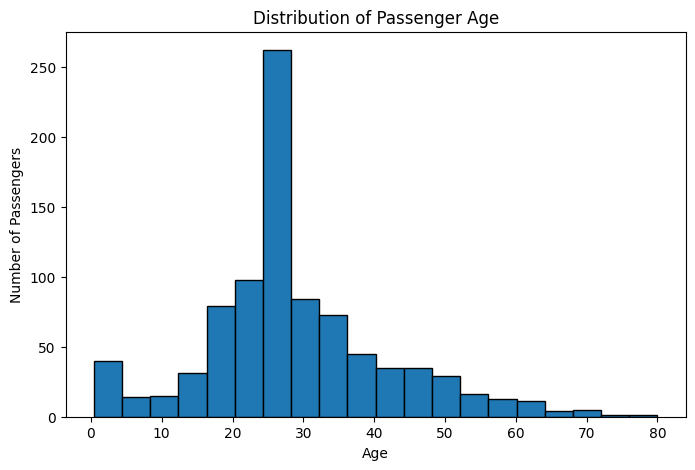

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Age"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

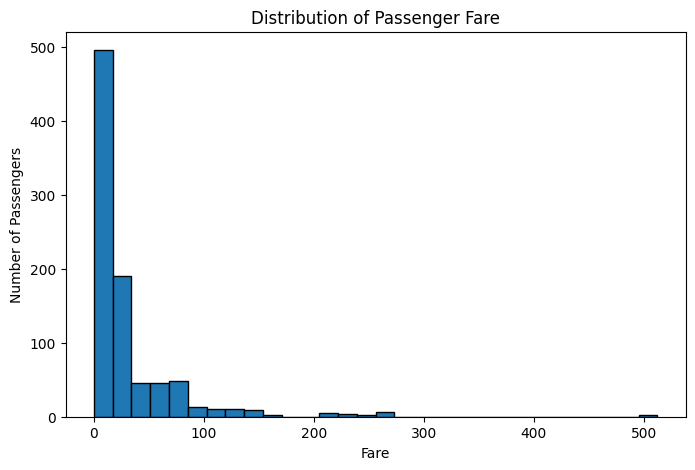

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Fare"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Passenger Fare")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

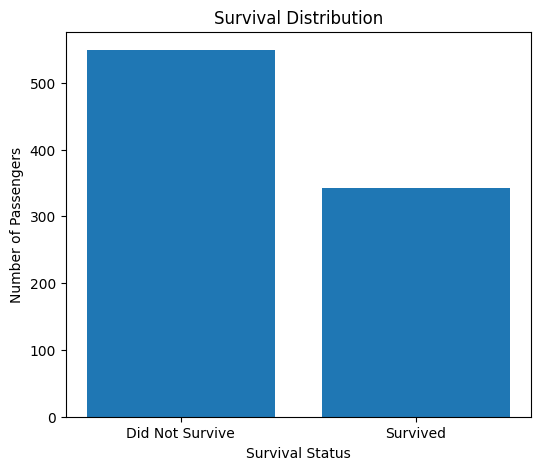

In [20]:
survival_counts = df["Survived"].value_counts()

plt.figure(figsize=(6, 5))

plt.bar(
    ["Did Not Survive", "Survived"],
    survival_counts.values
)

plt.title("Survival Distribution")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

plt.show()


Survival by Gender:
Survived    0    1
Sex               
female     81  233
male      468  109


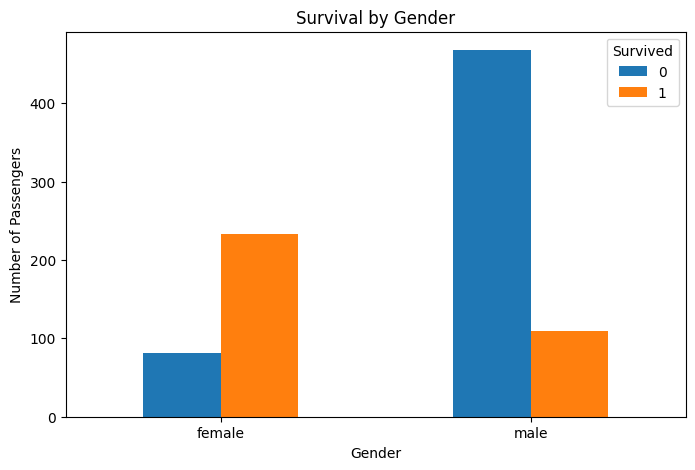

In [21]:
survival_gender = pd.crosstab(
    df["Sex"],
    df["Survived"]
)

print("\nSurvival by Gender:")
print(survival_gender)


plt.figure(figsize=(8, 5))

survival_gender.plot(
    kind="bar",
    ax=plt.gca()
)

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()



Survival by Passenger Class:
Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


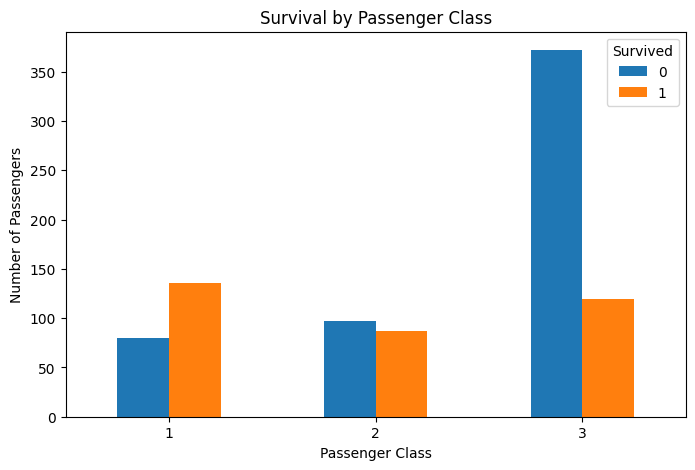

In [22]:
survival_class = pd.crosstab(
    df["Pclass"],
    df["Survived"]
)

print("\nSurvival by Passenger Class:")
print(survival_class)


plt.figure(figsize=(8, 5))

survival_class.plot(
    kind="bar",
    ax=plt.gca()
)

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()

In [23]:
numeric_df = df.select_dtypes(
    include=np.number
)

print("\nNumerical Columns:")
print(numeric_df.columns)



Numerical Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [24]:
correlation = numeric_df.corr()

print("\nCorrelation Matrix:")
print(correlation)


Correlation Matrix:
             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005007 -0.035144  0.034212 -0.057527 -0.001652   
Survived       -0.005007  1.000000 -0.338481 -0.064910 -0.035322  0.081629   
Pclass         -0.035144 -0.338481  1.000000 -0.339898  0.083081  0.018443   
Age             0.034212 -0.064910 -0.339898  1.000000 -0.233296 -0.172482   
SibSp          -0.057527 -0.035322  0.083081 -0.233296  1.000000  0.414838   
Parch          -0.001652  0.081629  0.018443 -0.172482  0.414838  1.000000   
Fare            0.012658  0.257307 -0.549500  0.096688  0.159651  0.216225   

                 Fare  
PassengerId  0.012658  
Survived     0.257307  
Pclass      -0.549500  
Age          0.096688  
SibSp        0.159651  
Parch        0.216225  
Fare         1.000000  


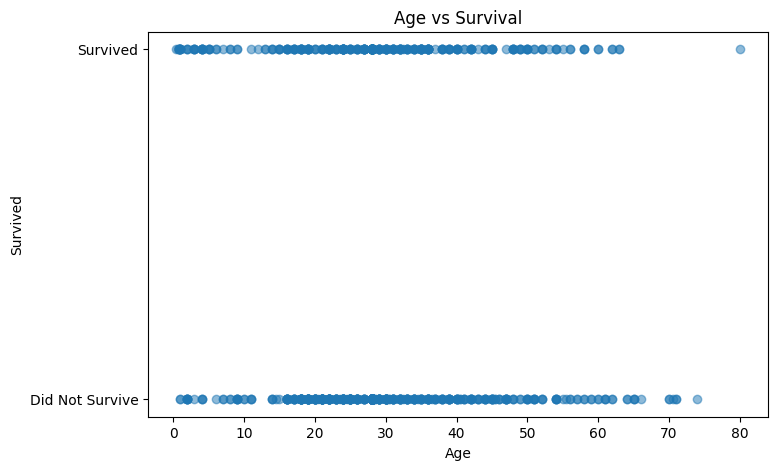

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Age"],
    df["Survived"],
    alpha=0.5
)

plt.title("Age vs Survival")
plt.xlabel("Age")
plt.ylabel("Survived")

plt.yticks(
    [0, 1],
    ["Did Not Survive", "Survived"]
)

plt.show()